# Multi-Class Benchmark Classification Pipeline (Iris)
**Task 1 – Datheon AI Internship**

End-to-end supervised classification on the Iris dataset: scaling, 80/20 split, Logistic Regression vs Decision Tree, with accuracy / precision / recall / F1, confusion matrices and decision boundaries.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load the Dataset

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df['species'].value_counts())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory Data Analysis (Seaborn Pairplot)

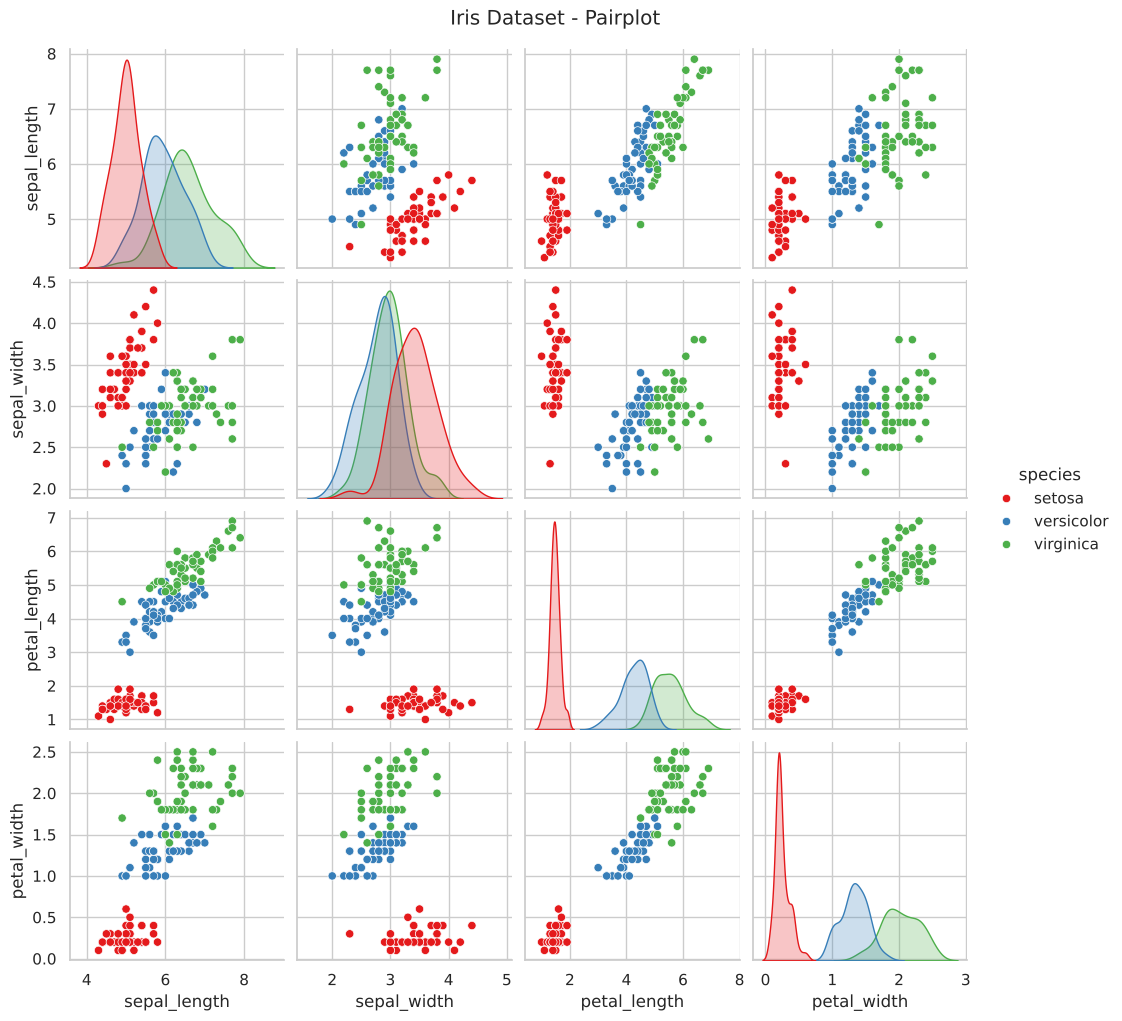

In [4]:
sns.pairplot(df, hue="species", palette="Set1", diag_kind="kde")
plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

## 4. Features / Target & Train-Test Split (80/20)

In [5]:
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120, 4) | Test: (30, 4)


## 5. Feature Scaling (StandardScaler)
Scaler is **fit only on training data** to avoid data leakage.

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train mean (approx 0):", X_train_s.mean(axis=0).round(3))
print("Train std  (approx 1):", X_train_s.std(axis=0).round(3))

Train mean (approx 0): [-0.  0.  0.  0.]
Train std  (approx 1): [1. 1. 1. 1.]


## 6. Train Models

In [7]:
log_reg = LogisticRegression(max_iter=200, random_state=42)
dtree = DecisionTreeClassifier(random_state=42)

log_reg.fit(X_train_s, y_train)
dtree.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": dtree}
preds = {name: m.predict(X_test_s) for name, m in models.items()}

## 7. Benchmark: Accuracy, Precision, Recall, F1

In [8]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [9]:
for name, y_pred in preds.items():
    print("="*60)
    print(name)
    print("="*60)
    print(classification_report(y_test, y_pred))

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



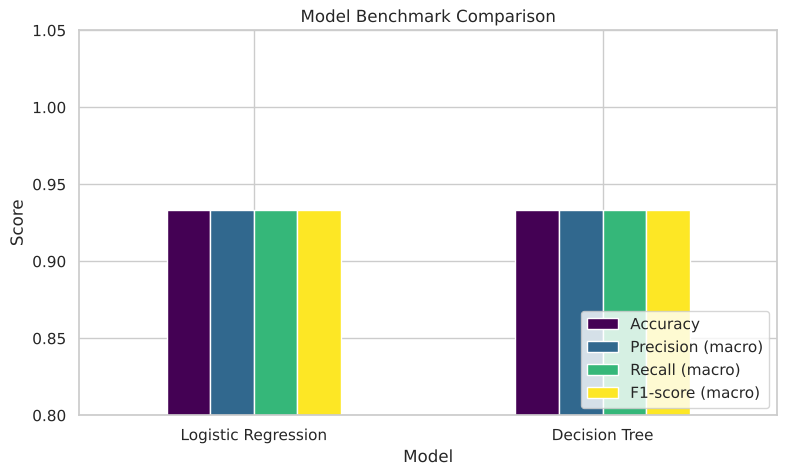

In [10]:
results.plot(kind="bar", figsize=(9, 5), ylim=(0.8, 1.05), colormap="viridis")
plt.title("Model Benchmark Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 8. Confusion Matrix Heatmaps

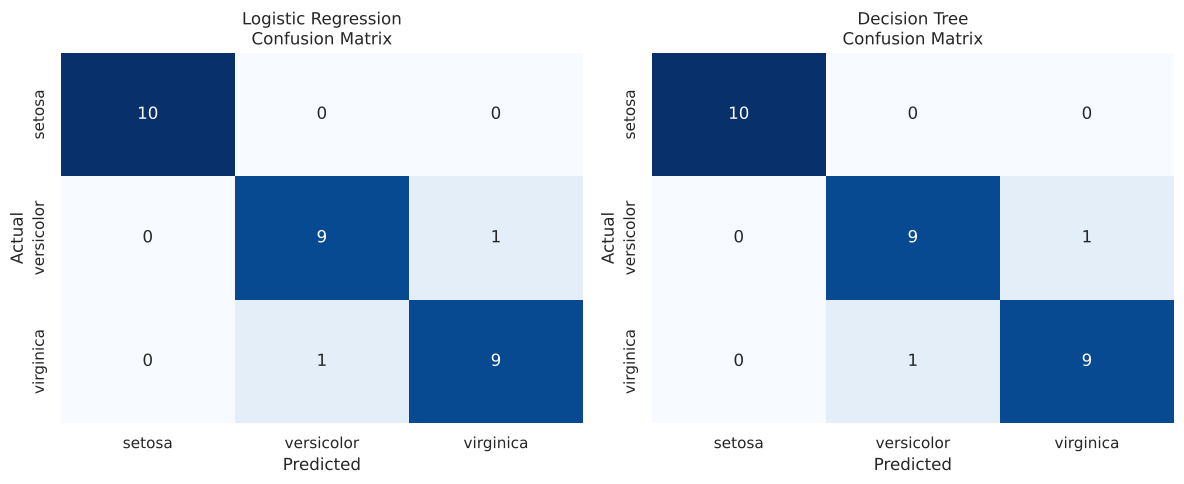

In [11]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 9. Decision Boundary Visualization
Decision boundaries need 2D input, so models are re-trained on the two most discriminative features: **petal_length** and **petal_width**.

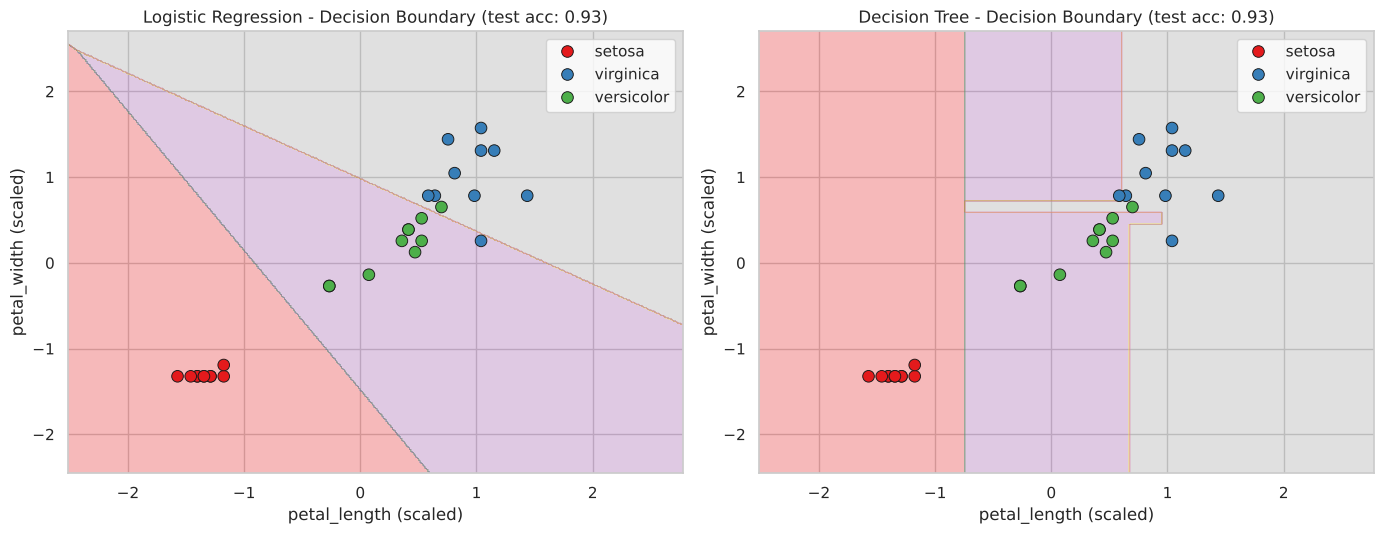

In [12]:
f1_name, f2_name = "petal_length", "petal_width"
X2 = df[[f1_name, f2_name]]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

sc2 = StandardScaler()
X2_tr_s = sc2.fit_transform(X2_tr)
X2_te_s = sc2.transform(X2_te)

classes = sorted(y.unique())
class_to_int = {c: i for i, c in enumerate(classes)}
y2_tr_i = y2_tr.map(class_to_int).values
y2_te_i = y2_te.map(class_to_int).values

boundary_models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

x_min, x_max = X2_tr_s[:, 0].min() - 1, X2_tr_s[:, 0].max() + 1
y_min, y_max = X2_tr_s[:, 1].min() - 1, X2_tr_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X2_tr_s, y2_tr_i)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    sns.scatterplot(x=X2_te_s[:, 0], y=X2_te_s[:, 1],
                    hue=[classes[i] for i in y2_te_i], palette="Set1",
                    edgecolor="k", s=70, ax=ax)
    acc = accuracy_score(y2_te_i, model.predict(X2_te_s))
    ax.set_title(f"{name} - Decision Boundary (test acc: {acc:.2f})")
    ax.set_xlabel(f"{f1_name} (scaled)")
    ax.set_ylabel(f"{f2_name} (scaled)")
plt.tight_layout()
plt.show()

## 10. Conclusion
- Both models were trained on standardized features with a stratified 80/20 split.
- Logistic Regression and Decision Tree were benchmarked on accuracy, precision, recall and F1 (macro-averaged); see the table in Section 7.
- Setosa is linearly separable and is classified perfectly; any errors occur between versicolor and virginica, whose classes overlap slightly.
- The decision boundary plots show Logistic Regression producing smooth linear boundaries, while the Decision Tree produces axis-aligned rectangular regions.